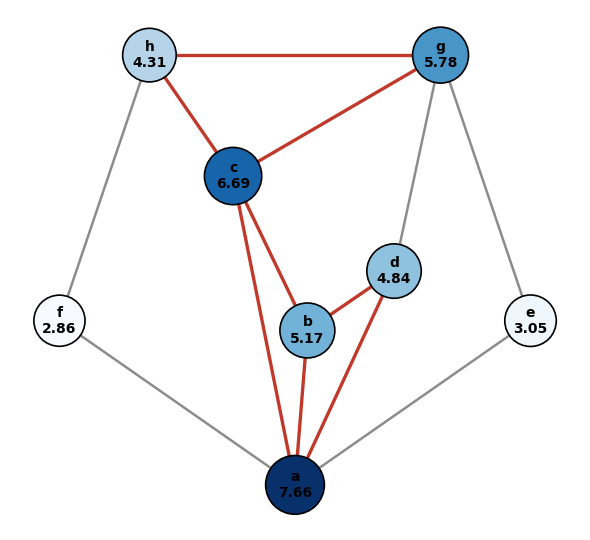

In [ ]:
import numpy as np, networkx as nx, matplotlib.pyplot as plt
from scipy.linalg import expm

edges = [('a','b'),('a','c'),('a','d'),('a','e'),('a','f'),('b','c'),('b','d'),('c','g'),('c','h'),('d','g'),('e','g'),('f','h'),('g','h')]
nodes = list("abcdefgh")
G = nx.Graph(); G.add_nodes_from(nodes); G.add_edges_from(edges)
A = nx.to_numpy_array(G, nodelist=nodes)
SC = np.diag(expm(A))                       # subgraph centrality at beta = 1

# fixed layout: outer pentagon a-f-h-g-e (a cycle of the graph), vertices c, d, b inside it
ang = {'a': 270, 'f': 198, 'h': 126, 'g': 54, 'e': 342}
pos = {v: (np.cos(np.radians(a)), np.sin(np.radians(a))) for v, a in ang.items()}
pos.update({'c': (-0.25, 0.30), 'd': (0.40, -0.10), 'b': (0.05, -0.35)})

# triangles: highlight the edges that lie on a triangle
tri_edges = set()
for a, b, c in (t for t in nx.enumerate_all_cliques(G) if len(t) == 3):
    tri_edges |= {frozenset(p) for p in [(a,b),(b,c),(a,c)]}
on_tri = [e for e in G.edges if frozenset(e) in tri_edges]
off_tri = [e for e in G.edges if frozenset(e) not in tri_edges]

fig, ax = plt.subplots(figsize=(6, 5.5))
nx.draw_networkx_edges(G, pos, edgelist=off_tri, width=1.8, edge_color="0.55", ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=on_tri, width=2.4, edge_color="#c0392b", ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_size=1100 + 90 * SC, node_color=SC, cmap="Blues",
                       edgecolors="black", linewidths=1.2, ax=ax)
nx.draw_networkx_labels(G, pos, labels={v: f"{v}\n{SC[i]:.2f}" for i, v in enumerate(nodes)}, font_size=10, font_weight="bold", ax=ax)
#ax.set_title("Non-bipartite benchmark graph (8 vertices, 13 edges, 3 triangles)\n"
             #"vertex label: name and SC(v) at β = 1;  red edges lie on a triangle", fontsize=10)
ax.axis("off"); fig.tight_layout()
fig.savefig("graph_X.png", dpi=200)
plt.show()

In [ ]:
#this cell defines our non-bipartite graph and determines its degrees/ranks using subgraph centrality, sc, calculated using networkx (nx.subgraph_centrality).
# we use it later to validate our exact SC (calculated using numpy)

import networkx as nx

# Define the graph (vertices a-h)
G = nx.Graph([
    ('a', 'b'), ('a', 'c'), ('a', 'd'), ('a', 'e'), ('a', 'f'),
    ('b', 'c'), ('b', 'd'),
    ('c', 'g'), ('c', 'h'),
    ('d', 'g'),
    ('e', 'g'),
    ('f', 'h'),
    ('g', 'h'),
])

print("bipartite?", nx.is_bipartite(G))                       # added: should be False (it has odd cycles)
print("triangles :", sum(nx.triangles(G).values()) // 3)      # added: should be 3

# Subgraph centrality
sc = nx.subgraph_centrality(G)

print("\nSubgraph centrality:")
for node in sorted(sc):
    print(f"{node}: {sc[node]:.6f}")

# Normalized subgraph centrality
# only added to guard against overflow for large lambda. Not used anywhere else in the pipeline
sc_norm = nx.subgraph_centrality(G, normalized=True)

print("\nNormalized subgraph centrality:")
for node in sorted(sc_norm):
    print(f"{node}: {sc_norm[node]:.6f}")

# Degree of each node
print("\nDegrees:")
for node in sorted(G.nodes()):
    print(f"{node}: {G.degree(node)}")

bipartite? False
triangles : 3

Subgraph centrality:
a: 7.664244
b: 5.165987
c: 6.687861
d: 4.839192
e: 3.045803
f: 2.855561
g: 5.778268
h: 4.313197

Normalized subgraph centrality:
a: 0.239670
b: 0.161546
c: 0.209137
d: 0.151327
e: 0.095246
f: 0.089297
g: 0.180693
h: 0.134879

Degrees:
a: 5
b: 3
c: 4
d: 3
e: 2
f: 2
g: 4
h: 3


In [ ]:
#this cell is for calculating SC using numpy. we use these SC values throughout the project
# for a non-bipartite graph SC = cosh part + sinh part, so both parts are also computed here
import networkx as nx
import numpy as np
from scipy.linalg import expm

G = nx.Graph([
    ('a', 'b'), ('a', 'c'), ('a', 'd'), ('a', 'e'), ('a', 'f'),
    ('b', 'c'), ('b', 'd'),
    ('c', 'g'), ('c', 'h'),
    ('d', 'g'),
    ('e', 'g'),
    ('f', 'h'),
    ('g', 'h'),
])

nodes = sorted(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)

beta = 1.0
E = expm(beta * A)
SC_exact = dict(zip(nodes, np.diag(E)))

for n in nodes:
    print(f"{n}: {SC_exact[n]:.6f}")

sc_nx = nx.subgraph_centrality(G)
print("max |difference| vs networkx:", max(abs(sc_nx[n]-SC_exact[n]) for n in nodes))

# added: the even (cosh) and odd (sinh) parts. Unlike the bipartite graph, the sinh part is not zero.
w, V = np.linalg.eigh(A)
cosh_part = np.diag((V * np.cosh(beta * w)) @ V.T)
sinh_part = np.diag((V * np.sinh(beta * w)) @ V.T)
print("\n  node   SC        cosh part  sinh part  sinh/SC")
for i, n in enumerate(nodes):
    print(f"  {n}   {SC_exact[n]:9.6f} {cosh_part[i]:9.6f} {sinh_part[i]:9.6f}  {sinh_part[i]/SC_exact[n]:.3f}")
print("max |cosh + sinh - SC|:", np.max(np.abs(cosh_part + sinh_part - np.diag(E))))


a: 7.664244
b: 5.165987
c: 6.687861
d: 4.839192
e: 3.045803
f: 2.855561
g: 5.778268
h: 4.313197
max |difference| vs networkx: 1.13509202037676e-12

  node   SC        cosh part  sinh part  sinh/SC
  a    7.664244  6.105459  1.558784  0.203
  b    5.165987  3.820919  1.345068  0.260
  c    6.687861  5.206255  1.481606  0.222
  d    4.839192  4.031255  0.807937  0.167
  e    3.045803  2.867537  0.178265  0.059
  f    2.855561  2.682250  0.173311  0.061
  g    5.778268  4.872588  0.905680  0.157
  h    4.313197  3.542011  0.771187  0.179
max |cosh + sinh - SC|: 1.13509202037676e-12


In [ ]:
#this cell normalizes the adjacency matrix and builds the Chebyshev polynomials for BOTH branches:
# even branch: cosh(z x)/cosh(z)   (closed walks of even length)
# odd  branch: sinh(z x)/sinh(z)   (closed walks of odd length; this part was zero for the bipartite graph)
#DELTA is the fixed target for the SC error of each branch. Each degree is the smallest one whose truncation error, multiplied by cosh(z) (even) or sinh(z) (odd), stays below DELTA.
#the same DELTA is used in every later cell of this notebook, and it is chosen without looking at any classical score.
import numpy as np
from scipy.special import ive
from numpy.polynomial import chebyshev as C

DELTA = 1e-4   # target absolute error on the SC scale; SC(v) >= 1 for unweighted graphs, so it also bounds the relative error

# ---------- normalize the adjacency matrix ----------
beta = 1.0
lam = np.max(np.abs(np.linalg.eigvalsh(A)))                    # spectral norm of A
alpha = 1.001 * max(lam, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))   # also covers PennyLane's BlockEncode rule
z = beta * alpha
print(f"spectral norm = {lam:.6f}   alpha = {alpha:.6f}   z = beta*alpha = {z:.6f}")
print(f"cosh(z) = {np.cosh(z):.4f}   sinh(z) = {np.sinh(z):.4f}\n")

# ---------- Chebyshev (Bessel) coefficients ----------
def cheb_coeffs(z, deg, parity):
    """weights of T_0, T_1, ..., T_deg.
    parity = 0: target cosh(zx)/cosh(z), only even degrees are non-zero
    parity = 1: target sinh(zx)/sinh(z), only odd degrees are non-zero"""
    k = np.arange(deg + 1)                         # polynomial degrees
    c = 2.0 * ive(k, z)                            # Bessel weights, scaled by e^-z because of ive
    c[0] = ive(0, z)                               # T0 has no factor 2 (it is masked out below for the odd branch)
    c[k % 2 != parity] = 0.0                       # keep only the degrees of the right parity
    if parity == 0:
        return c / (0.5 * (1 + np.exp(-2 * z)))    # divide by cosh(z), scaled by e^-z to match ive
    return c / (0.5 * (1 - np.exp(-2 * z)))        # divide by sinh(z), scaled by e^-z to match ive

def tail_error(z, deg, parity):
    """exact worst-case error = sum of the discarded weights"""
    c_full = cheb_coeffs(z, deg + 60, parity)      # same function with 60 more terms
    return float(np.sum(np.abs(c_full[deg + 1:])))

def degree_for_eps(z, eps, parity, max_deg=200):   # determining up to how many degrees to keep
    d = parity                                     # even branch starts at 0, odd branch at 1
    while tail_error(z, d, parity) > eps:
        d += 2                                     # each branch only uses its own parity
        if d > max_deg:
            raise RuntimeError("tolerance not reached; raise max_deg")
    return d, cheb_coeffs(z, d, parity)

d_e, c_e = degree_for_eps(z, DELTA / np.cosh(z), parity=0)
d_o, c_o = degree_for_eps(z, DELTA / np.sinh(z), parity=1)
print(f"even branch degree: {d_e}   tail error: {tail_error(z, d_e, 0):.3e}")
print(f"  weights on T0, T2, T4, ...: {np.round(c_e[::2], 6)}")
print(f"odd  branch degree: {d_o}   tail error: {tail_error(z, d_o, 1):.3e}")
print(f"  weights on T1, T3, T5, ...: {np.round(c_o[1::2], 6)}\n")

# ---------- verify admissibility ----------
def check_admissibility(c, z, parity):
    xs = np.linspace(-1, 1, 200_001)               # the grid of test points
    P = C.chebval(xs, c)                           # the polynomial at every grid point
    if parity == 0:
        target = np.cosh(z * xs) / np.cosh(z)      # the exact function at every grid point
        name, sign = "even (cosh)", 1
    else:
        target = np.sinh(z * xs) / np.sinh(z)
        name, sign = "odd (sinh)", -1

    grid_error = np.max(np.abs(P - target))
    parity_violation = np.max(np.abs(C.chebval(-xs, c) - sign * P))   # even: P(-x) = P(x); odd: P(-x) = -P(x)
    max_abs_P = np.max(np.abs(P))
    admissible = max_abs_P <= 1.0

    print(f"{name} branch:")
    print(f"  1. grid evaluation : worst-case error vs target = {grid_error:.3e}")
    print(f"  2. parity check    : max deviation = {parity_violation:.2e}  "
          f"-> {'OK' if parity_violation < 1e-9 else 'FAILED'}")
    print(f"  3. admissibility   : max|P(x)| = {max_abs_P:.10f}  "
          f"-> {'OK, no scaling needed' if admissible else 'OVERSHOOT -- needs delta scaling'}")

    c_safe, delta = c, 0.0
    if not admissible:
        delta = (1.0 - 1.0 / max_abs_P) * 1.01
        c_safe = c * (1 - delta)
        print(f"     applying delta = {delta:.2e}; divide recovered amplitude by {1-delta:.6f} later")
    return c_safe, delta

c_e_safe, delta_e = check_admissibility(c_e, z, parity=0)
c_o_safe, delta_o = check_admissibility(c_o, z, parity=1)
print(f"\nSC error bound, even part: cosh(z) * tail error = {np.cosh(z) * tail_error(z, d_e, 0):.2e}")
print(f"SC error bound, odd  part: sinh(z) * tail error = {np.sinh(z) * tail_error(z, d_o, 1):.2e}")

spectral norm = 3.465060   alpha = 3.876856   z = beta*alpha = 3.876856
cosh(z) = 24.1465   sinh(z) = 24.1258

even branch degree: 10   tail error: 6.610e-07
  weights on T0, T2, T4, ...: [4.20966e-01 4.69003e-01 9.91240e-02 1.02660e-02 6.17000e-04 2.40000e-05]
odd  branch degree: 11   tail error: 9.643e-08
  weights on T1, T3, T5, ...: [7.23515e-01 2.39200e-01 3.44790e-02 2.67400e-03 1.28000e-04 4.00000e-06]

even (cosh) branch:
  1. grid evaluation : worst-case error vs target = 6.610e-07
  2. parity check    : max deviation = 0.00e+00  -> OK
  3. admissibility   : max|P(x)| = 0.9999993390  -> OK, no scaling needed
odd (sinh) branch:
  1. grid evaluation : worst-case error vs target = 9.643e-08
  2. parity check    : max deviation = 0.00e+00  -> OK
  3. admissibility   : max|P(x)| = 0.9999999036  -> OK, no scaling needed

SC error bound, even part: cosh(z) * tail error = 1.60e-05
SC error bound, odd  part: sinh(z) * tail error = 2.33e-06


In [ ]:
!pip install pennylane

In [ ]:
# this cell is blockencoding the adjacency matrix using pennylane's function
import numpy as np, pennylane as qml
from scipy.linalg import expm

beta = 1.0
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))  # 3.876856
z = beta * alpha
At = A / alpha
print("alpha =", alpha, " norm(At) =", np.linalg.norm(At, 2)) #checking to make sure the norm is less than 1

BE = qml.BlockEncode(At, wires=range(4)) # the unitary matrix is a 2^4x2^4 (4 qubits, hilbert space dim=16)
U = qml.matrix(BE)
print("U shape:", U.shape)
print("unitary error:", np.abs(U @ U.conj().T - np.eye(16)).max())
print("top-left block equals At:", np.allclose(U[:8, :8], At))


alpha = 3.876856329553624  norm(At) = 0.8937808967970242
U shape: (16, 16)
unitary error: 1.6653345369377348e-15
top-left block equals At: True


In [ ]:
#this cell finds the QSVT angles for the even polynomial (degree d_e) and the odd polynomial (degree d_o), both set by DELTA in the polynomial cell, checks that each QSVT circuit applies its
#polynomial to Ã, then averages each circuit with its mirror to get the real part and compares the SC estimates with the exact ones.
#the even circuit estimates the cosh part, the odd circuit estimates the sinh part, and SC = cosh part + sinh part.

poly_e = C.cheb2poly(c_e)                      # monomial form needed for PennyLane
poly_o = C.cheb2poly(c_o)
angles_e = qml.poly_to_angles(poly_e, "QSVT")  # classical phase finding: solves the angles for us
angles_o = qml.poly_to_angles(poly_o, "QSVT")
print("degrees: even", d_e, "  odd", d_o, "   number of angles: even", len(angles_e), "  odd", len(angles_o))      # one more angle than the degree

def qsvt_block(ang):
    projs = [qml.PCPhase(a, dim=8, wires=range(4)) for a in ang]  ## one phase gate (a 16x16 matrix) per angle, vertex states get e^(+ia), the other 8 get e^(-ia)
    M = qml.matrix(qml.QSVT(BE, projs), wire_order=range(4))      # QSVT(BE, projs) alternates the Ã box (BE) with the phase gates
    return M[:8, :8]                                              # we keep only the top-left 8x8 corner

w, V = np.linalg.eigh(At)
SC_ex = np.diag(expm(beta * A))                # exact SC (numpy)
CH_ex = cosh_part                              # exact cosh part (from Cell 2)
SH_ex = sinh_part                              # exact sinh part (from Cell 2)

def run_branch(name, c, angles, scale, exact_part):
    blk = qsvt_block(angles)                   # runs the qsvt circuit
    P_At = (V * C.chebval(w, c)) @ V.T         # classically calculated exact P(Ã)
    print(f"{name}:")
    print("  max |imag(block)|        :", np.abs(blk.imag).max())              # the raw circuit output is complex, so the real-part trick is needed
    print("  max |real(block) - P(Ã)| :", np.abs(blk.real - P_At).max())
    # real part: average the circuit with its mirror (negated angles)
    blk_re = (blk + qsvt_block(-np.array(angles))) / 2
    est = scale * np.diag(blk_re).real         # the circuit's estimate of this part of SC
    print("  max abs error on this part:", np.abs(est - exact_part).max())
    return est

est_e = run_branch("even (cosh) branch", c_e, angles_e, np.cosh(z), CH_ex)
est_o = run_branch("odd (sinh) branch ", c_o, angles_o, np.sinh(z), SH_ex)

sc_est = est_e + est_o
print("\nSC exact  :", np.round(SC_ex, 6))
print("SC circuit:", np.round(sc_est, 6))
print("max abs error (even + odd):", np.abs(sc_est - SC_ex).max())
print("max rel error             :", np.max(np.abs(sc_est - SC_ex) / SC_ex))
names = sorted(G.nodes())
rank = lambda x: [names[i] for i in np.argsort(-x)]   # vertex names from highest to lowest
print("ranking exact  :", rank(SC_ex))
print("ranking circuit:", rank(sc_est))
print("ranking from the even part alone:", rank(est_e))

degrees: even 10   odd 11    number of angles: even 11   odd 12
even (cosh) branch:
  max |imag(block)|        : 0.6195836797579181
  max |real(block) - P(Ã)| : 2.5307533846330443e-13
  max abs error on this part: 4.546721653397867e-06
odd (sinh) branch :
  max |imag(block)|        : 0.5338090215088748
  max |real(block) - P(Ã)| : 1.8265944312645388e-13
  max abs error on this part: 1.5376051845372718e-06

SC exact  : [7.664244 5.165987 6.687861 4.839192 3.045803 2.855561 5.778268 4.313197]
SC circuit: [7.664244 5.165989 6.687857 4.839188 3.045802 2.85556  5.778269 4.313197]
max abs error (even + odd): 4.416261660367127e-06
max rel error             : 9.126031172894633e-07
ranking exact  : ['a', 'c', 'g', 'b', 'd', 'h', 'e', 'f']
ranking circuit: ['a', 'c', 'g', 'b', 'd', 'h', 'e', 'f']
ranking from the even part alone: ['a', 'c', 'g', 'd', 'b', 'h', 'e', 'f']


In [ ]:
#This cell is the Step 15 unit test of the odd (sinh) branch on two tiny graphs before it is trusted on the 8-vertex graph: a triangle K3 and a triangle with one pendant vertex.
#For each graph it builds the odd polynomial at the fixed target DELTA, runs the QSVT circuit (real part: average with the mirror circuit) and compares <v|P_o(Ã)|v> with the exact [sinh(βA)]_vv / sinh(βα).
#The same is done for the even branch and for the recombined SC, so a sign-convention error in either parity would show up here. All variables are local to this cell.
def tiny_graph_test(name, edges, beta=1.0):
    G_s = nx.Graph(edges)
    nodes_s = sorted(G_s.nodes())
    n = len(nodes_s)
    nq = int(np.ceil(np.log2(n)))                      # qubits for the vertex register
    Nd = 2 ** nq                                       # padded size; dummy vertices are isolated
    A_s = np.zeros((Nd, Nd)); A_s[:n, :n] = nx.to_numpy_array(G_s, nodelist=nodes_s, weight=None)
    lam_s = np.max(np.abs(np.linalg.eigvalsh(A_s)))
    alpha_s = 1.001 * max(lam_s, np.sqrt(np.max(np.abs(A_s @ A_s).sum(axis=1))))
    z_s = beta * alpha_s
    At_s = A_s / alpha_s
    wires = list(range(nq + 1))                        # nq register qubits + 1 block-encoding ancilla
    BE_s = qml.BlockEncode(At_s, wires=wires)
    w_s, V_s = np.linalg.eigh(A_s)
    exact = {"even": (V_s * np.cosh(beta * w_s)) @ V_s.T / np.cosh(z_s),     # [cosh(βA)] / cosh(βα)
             "odd":  (V_s * np.sinh(beta * w_s)) @ V_s.T / np.sinh(z_s)}     # [sinh(βA)] / sinh(βα)
    scale = {"even": np.cosh(z_s), "odd": np.sinh(z_s)}
    est = {}
    print(f"{name}: {n} vertices, {G_s.number_of_edges()} edges, padded to {Nd}, alpha = {alpha_s:.4f}, z = {z_s:.4f}")
    for parity, label in [(0, "even"), (1, "odd")]:
        deg = parity
        while tail_error(z_s, deg, parity) > DELTA / scale[label]: deg += 2      # fixed target, same rule as everywhere else
        c_s = cheb_coeffs(z_s, deg, parity)
        ang = qml.poly_to_angles(C.cheb2poly(c_s), "QSVT")
        def blk(a):
            projs = [qml.PCPhase(x, dim=Nd, wires=wires) for x in a]
            return qml.matrix(qml.QSVT(BE_s, projs), wire_order=wires)[:Nd, :Nd]
        b = (blk(ang) + blk(-np.array(ang))) / 2                                 # real part
        circ = np.diag(b).real
        est[label] = scale[label] * circ
        print(f"  {label} branch, degree {deg}:  max |<v|P(Ã)|v> - exact normalized| = {np.max(np.abs(circ - np.diag(exact[label])))[()]:.2e}"
              f"   min <v|P(Ã)|v> = {circ[:n].min():.4f} (should be >= 0)")
    sc_ex = np.diag(expm(beta * A_s))
    print("  vertex | exact sinh part | circuit sinh part | exact SC  | circuit SC (cosh + sinh)")
    for i in range(n):
        print(f"  {nodes_s[i]:>6} | {scale['odd'] * exact['odd'][i, i]:>15.6f} | {est['odd'][i]:>17.6f} | {sc_ex[i]:>9.6f} | {est['even'][i] + est['odd'][i]:>24.6f}")
    print(f"  max abs SC error = {np.max(np.abs(est['even'][:n] + est['odd'][:n] - sc_ex[:n])):.2e}\n")

tiny_graph_test("triangle K3", [("a", "b"), ("b", "c"), ("a", "c")])
tiny_graph_test("triangle + pendant vertex", [("a", "b"), ("b", "c"), ("a", "c"), ("c", "d")])

triangle K3: 3 vertices, 3 edges, padded to 4, alpha = 2.0020, z = 2.0020
  even branch, degree 6:  max |<v|P(Ã)|v> - exact normalized| = 1.47e-05   min <v|P(Ã)|v> = 0.6056 (should be >= 0)
  odd branch, degree 7:  max |<v|P(Ã)|v> - exact normalized| = 1.65e-06   min <v|P(Ã)|v> = 0.1171 (should be >= 0)
  vertex | exact sinh part | circuit sinh part | exact SC  | circuit SC (cosh + sinh)
       a |        0.425486 |          0.425480 |  2.708272 |                 2.708267
       b |        0.425486 |          0.425480 |  2.708272 |                 2.708267
       c |        0.425486 |          0.425480 |  2.708272 |                 2.708267
  max abs SC error = 4.64e-06

triangle + pendant vertex: 4 vertices, 4 edges, padded to 4, alpha = 2.2383, z = 2.2383
  even branch, degree 8:  max |<v|P(Ã)|v> - exact normalized| = 2.57e-07   min <v|P(Ã)|v> = 0.3461 (should be >= 0)
  odd branch, degree 7:  max |<v|P(Ã)|v> - exact normalized| = 1.93e-06   min <v|P(Ã)|v> = 0.0042 (should be >= 0)
 

even (cosh) branch, degree 10:
  max |response - P|      : 9.99644811372491e-13
  max |response - target| : 6.609708612659304e-07
odd (sinh) branch, degree 11:
  max |response - P|      : 9.99866855977416e-13
  max |response - target| : 9.6431145513165e-08


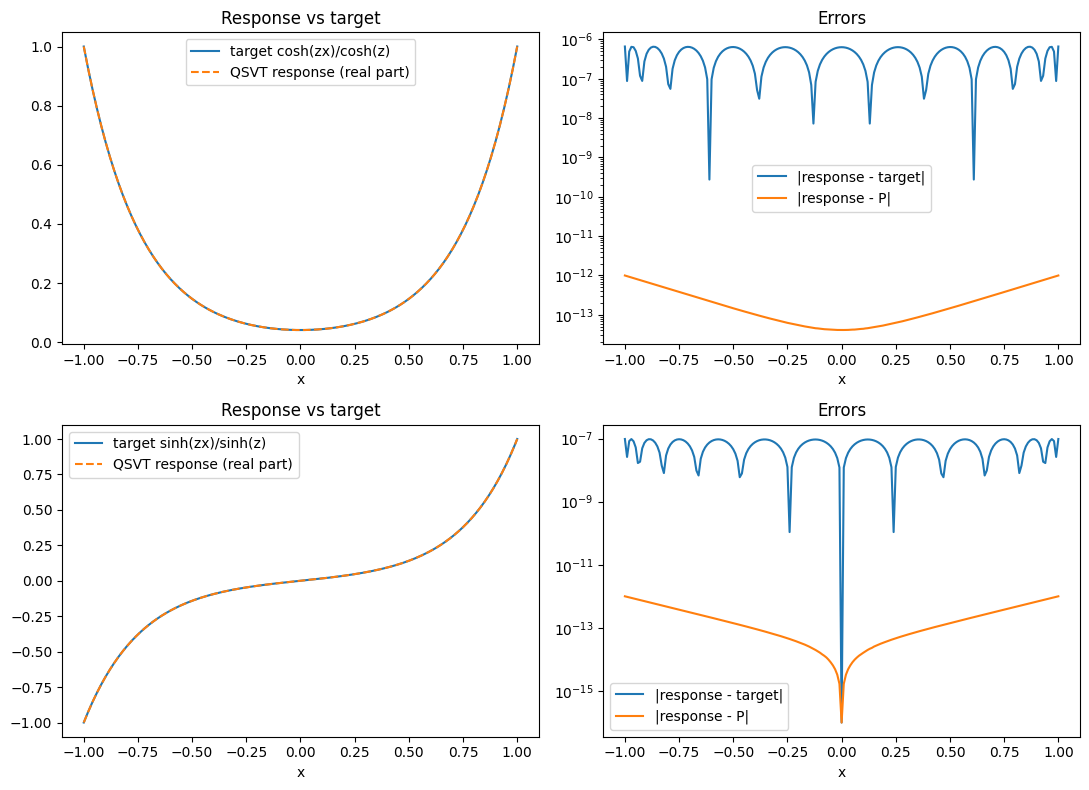

In [ ]:
import matplotlib.pyplot as plt
#For this response plot only, we replace the matrix Ã with a single number x and sweep x across [−1, 1]
#done for both polynomials: the even one (cosh) and the odd one (sinh)
def response_at(x, ang):
    be = qml.BlockEncode(np.array([[x]]), wires=[0])
    projs = [qml.PCPhase(a, dim=1, wires=[0]) for a in ang]
    return qml.matrix(qml.QSVT(be, projs), wire_order=[0])[0, 0]

xs = np.linspace(-1, 1, 201)

def response_check(name, c, angles, target):
    r1 = np.array([response_at(x, angles) for x in xs])
    r2 = np.array([response_at(x, -np.array(angles)) for x in xs])
    resp = ((r1 + r2) / 2).real             # real-part average, as before
    P = C.chebval(xs, c)                    # the polynomial
    print(f"{name}:")
    print("  max |response - P|      :", np.abs(resp - P).max())        # checking if the circuit matches our polynomial almost exactly, i.e. if the angles are correct
    print("  max |response - target| :", np.abs(resp - target).max())   # the truncation error
    return resp, P

target_e = np.cosh(z * xs) / np.cosh(z)     # exact functions
target_o = np.sinh(z * xs) / np.sinh(z)
resp_e, P_e = response_check(f"even (cosh) branch, degree {d_e}", c_e, angles_e, target_e)
resp_o, P_o = response_check(f"odd (sinh) branch, degree {d_o}", c_o, angles_o, target_o)

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for row, (resp, P, target, label) in enumerate([(resp_e, P_e, target_e, "cosh(zx)/cosh(z)"),
                                                 (resp_o, P_o, target_o, "sinh(zx)/sinh(z)")]):
    ax[row, 0].plot(xs, target, label="target " + label)
    ax[row, 0].plot(xs, resp, "--", label="QSVT response (real part)")
    ax[row, 0].legend(); ax[row, 0].set_xlabel("x"); ax[row, 0].set_title("Response vs target")
    ax[row, 1].semilogy(xs, np.abs(resp - target) + 1e-16, label="|response - target|")
    ax[row, 1].semilogy(xs, np.abs(resp - P) + 1e-16, label="|response - P|")
    ax[row, 1].legend(); ax[row, 1].set_xlabel("x"); ax[row, 1].set_title("Errors")
plt.tight_layout(); plt.show()

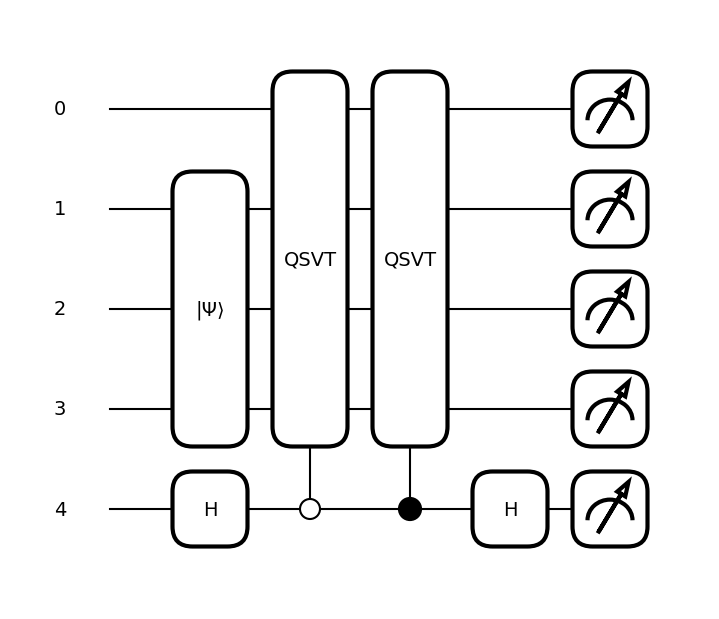

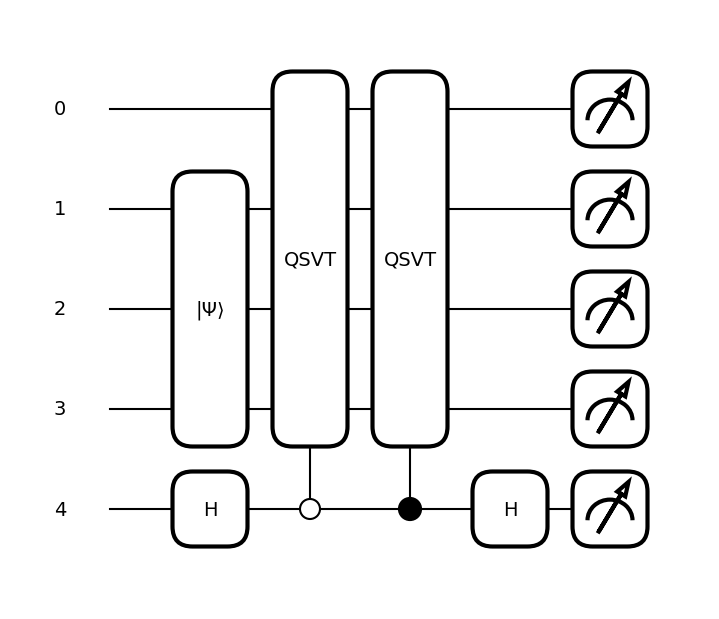

vertices             : ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h']
p_success even       : [0.0639 0.025  0.0465 0.0279 0.0141 0.0123 0.0407 0.0215]
p_success odd        : [4.175e-03 3.108e-03 3.771e-03 1.121e-03 5.500e-05 5.200e-05 1.409e-03
 1.022e-03]
cosh(z)*sqrt(p_even) : [6.105461 3.820922 5.206253 4.031251 2.867538 2.682249 4.872589 3.54201 ]
cosh part exact      : [6.105459 3.820919 5.206255 4.031255 2.867537 2.68225  4.872588 3.542011]
sinh(z)*sqrt(p_odd)  : [1.558783 1.345067 1.481605 0.807937 0.178264 0.173311 0.905679 0.771187]
sinh part exact      : [1.558784 1.345068 1.481606 0.807937 0.178265 0.173311 0.90568  0.771187]
SC from the circuits : [7.664244 5.165989 6.687857 4.839188 3.045802 2.85556  5.778269 4.313197]
SC exact             : [7.664244 5.165987 6.687861 4.839192 3.045803 2.855561 5.778268 4.313197]
max abs error        : 4.416261661255305e-06
max |circuit - Cell 6 estimate| : 2.6645352591003757e-15


In [ ]:
#this cell builds the 5-qubit real-part circuit for BOTH branches (drawn as circuit_5q_even.png and circuit_5q_odd.png)
#and reads the success probability for each vertex. The even circuit gives the cosh part of SC and the odd circuit gives the sinh part.
import matplotlib.pyplot as plt
N = 8
sc_exact = np.diag(expm(beta * A))

dev5 = qml.device("default.qubit", wires=5)   # a simulated quantum computer with 5 qubits. wires 0-3: block encoding, wire 4: real-part ancilla

def build_real_part_circuit(angles):
    projs_pos = [qml.PCPhase(a,  dim=N, wires=range(4)) for a in angles]   # the phase gates with the angles
    projs_neg = [qml.PCPhase(-a, dim=N, wires=range(4)) for a in angles]   # the phase gates with the negated angles

    @qml.qnode(dev5)   # makes the function a circuit
    def real_part_circuit(v):
        bits = [int(b) for b in format(v, "03b")]                 # turns the vertex number into 3 bits
        qml.BasisState(np.array(bits), wires=[1, 2, 3])           # input vertex |v>
        qml.Hadamard(wires=4)                                     # the first H on wire 4
        qml.ctrl(qml.QSVT(BE, projs_pos), control=4, control_values=[0])   # runs only if wire 4 is 0, with the angles
        qml.ctrl(qml.QSVT(BE, projs_neg), control=4, control_values=[1])   # runs only if wire 4 is 1, with the negated angles
        qml.Hadamard(wires=4)                                     # the last H on wire 4: merges the two branches, so the imaginary parts cancel
        return qml.probs(wires=range(5))                          # probability of each of the 32 outcomes of the 5 qubits
    return real_part_circuit

circ_e = build_real_part_circuit(angles_e)    # even branch (cosh part)
circ_o = build_real_part_circuit(angles_o)    # odd branch (sinh part)

for name, circ in [("even", circ_e), ("odd", circ_o)]:
    fig, ax = qml.draw_mpl(circ, style="black_white")(5)          # 5 = the vertex number
    fig.savefig(f"circuit_5q_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def p_success(circ, v):    # run the circuit starting at vertex v and read the one outcome that corresponds to a closed walk
    probs = circ(v)
    bits = [0] + [int(b) for b in format(v, "03b")] + [0]         # wire0=0, system=v, wire4=0
    return probs[int("".join(map(str, bits)), 2)]

p_e = np.array([p_success(circ_e, v) for v in range(N)])
p_o = np.array([p_success(circ_o, v) for v in range(N)])
est5_e = np.cosh(z) * np.sqrt(p_e)            # cosh part of SC
est5_o = np.sinh(z) * np.sqrt(p_o)            # sinh part of SC
est5 = est5_e + est5_o                        # SC = cosh part + sinh part

print("vertices             :", names)
print("p_success even       :", np.round(p_e, 4))
print("p_success odd        :", np.round(p_o, 6))
print("cosh(z)*sqrt(p_even) :", np.round(est5_e, 6))
print("cosh part exact      :", np.round(cosh_part, 6))
print("sinh(z)*sqrt(p_odd)  :", np.round(est5_o, 6))
print("sinh part exact      :", np.round(sinh_part, 6))
print("SC from the circuits :", np.round(est5, 6))
print("SC exact             :", np.round(sc_exact, 6))
print("max abs error        :", np.abs(est5 - sc_exact).max())
print("max |circuit - Cell 6 estimate| :", np.abs(est5 - sc_est).max())   # should be ~0: same polynomials, different circuit

In [ ]:
#this cell simulates finite shots for the two circuits to find how many are needed to get the vertex ranking right.
#each circuit is run n times per vertex (n = shots per circuit), so the total is 2n shots per vertex.
#repeating a circuit n times = binomial sampling with the success probability p (p_e for the even circuit, p_o for the odd one).
rng = np.random.default_rng(1)
true_order = np.argsort(-sc_exact)
print("true ranking:", [names[i] for i in true_order])
i_b, i_d = names.index("b"), names.index("d")      # the pair the odd branch fixes: b is above d (the even part alone gets it wrong)
i_e, i_f = names.index("e"), names.index("f")      # the closest pair (6.3% apart): e is above f
trials = 2000
print(f"{'shots/circuit':>13} | {'full ranking ok':>15} | {'b>d ok':>7} | {'e>f ok':>7} | {'mean abs SC err':>15}")
for n in [100, 1000, 10_000, 100_000, 1_000_000, 10_000_000]:
    counts_e = rng.binomial(n, p_e, size=(trials, N))
    counts_o = rng.binomial(n, p_o, size=(trials, N))
    est = np.cosh(z) * np.sqrt(counts_e / n) + np.sinh(z) * np.sqrt(counts_o / n)   # SC = cosh part + sinh part
    rank_ok = np.mean([np.array_equal(np.argsort(-e), true_order) for e in est])
    bd_ok = np.mean(est[:, i_b] > est[:, i_d])
    ef_ok = np.mean(est[:, i_e] > est[:, i_f])
    err = np.mean(np.abs(est - sc_exact))
    print(f"{n:>13} | {rank_ok:>15.3f} | {bd_ok:>7.3f} | {ef_ok:>7.3f} | {err:>15.4f}")

true ranking: ['a', 'c', 'g', 'b', 'd', 'h', 'e', 'f']
shots/circuit | full ranking ok |  b>d ok |  e>f ok | mean abs SC err
          100 |           0.001 |   0.496 |   0.415 |          1.4579
         1000 |           0.095 |   0.684 |   0.577 |          0.4508
        10000 |           0.691 |   0.906 |   0.780 |          0.1417
       100000 |           0.992 |   1.000 |   0.992 |          0.0430
      1000000 |           1.000 |   1.000 |   1.000 |          0.0135
     10000000 |           1.000 |   1.000 |   1.000 |          0.0042


In [ ]:
#This cell covers Step 18 for the two circuits: it turns simulated shot counts into estimates of the success probabilities p_even and p_odd and of SC(v) = cosh(z)*sqrt(p_even) + sinh(z)*sqrt(p_odd),
#and reports the bias of the square-root estimator, confidence intervals for SC (at least 95% coverage, conservative), and vertices left unresolved. It uses p_e and p_o from the 5-qubit circuit cell (run that cell first).
#The exact SC values are not used: the value the two circuits encode is the target of the statistics. Shots are per circuit, so each vertex uses twice that many in total.
beta_s = 1.0
z_s = beta_s * alpha
assert np.max(np.abs(np.cosh(z_s) * np.sqrt(p_e) + np.sinh(z_s) * np.sqrt(p_o) - np.diag(expm(beta_s * A)))) < 1e-3, "p_e and p_o do not belong to beta = 1.0; rerun the 5-qubit circuit cell"

sc_circ = np.cosh(z_s) * np.sqrt(p_e) + np.sinh(z_s) * np.sqrt(p_o)     # value the circuits encode for each vertex
rng18 = np.random.default_rng(18)
trials = 2000
Z = 2.2414          # two-sided 97.47% per branch, so that the two intervals together cover at least 95%

def wilson(k, n):
    """Wilson interval for a success probability from k successes in n shots; valid also for k = 0"""
    ph = k / n
    centre = (ph + Z**2 / (2 * n)) / (1 + Z**2 / n)
    half = Z * np.sqrt(ph * (1 - ph) / n + Z**2 / (4 * n**2)) / (1 + Z**2 / n)
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)

je, jo = int(np.argmin(p_e)), int(np.argmin(p_o))
print(f"weakest vertex, even circuit: {names[je]}  p = {p_e.min():.4f};   odd circuit: {names[jo]}  p = {p_o.min():.2e}   (guideline: n_s * p comfortably above 10-20)\n")
print(f"{'shots/circuit':>13} | {'min n*p even':>12} | {'min n*p odd':>11} | {'runs with an unresolved vertex':>30} | {'bias of weakest odd amplitude (measured / predicted)':>52} | {'interval coverage (target >= 95%)':>34}")
for n in [100, 1000, 10_000, 100_000, 1_000_000]:
    ke = rng18.binomial(n, p_e, size=(trials, N))             # successful events per vertex, even circuit
    ko = rng18.binomial(n, p_o, size=(trials, N))             # successful events per vertex, odd circuit
    unresolved = np.mean(((ke == 0) | (ko == 0)).any(axis=1))  # a vertex with no successful event in a circuit is unresolved, not zero
    bias_meas = np.sqrt(ko[:, jo] / n).mean() / np.sqrt(p_o[jo]) - 1
    bias_pred = -1 / (8 * n * p_o[jo])
    loe, hie = wilson(ke, n); loo, hio = wilson(ko, n)
    lo = np.cosh(z_s) * np.sqrt(loe) + np.sinh(z_s) * np.sqrt(loo)
    hi = np.cosh(z_s) * np.sqrt(hie) + np.sinh(z_s) * np.sqrt(hio)
    covered = (lo <= sc_circ) & (sc_circ <= hi)
    print(f"{n:>13} | {n * p_e.min():>12.1f} | {n * p_o.min():>11.1f} | {unresolved:>29.1%} | {bias_meas:>+27.4f} / {bias_pred:<+22.4f} | {covered.mean():>34.1%}")

# one example experiment at 10^5 shots per circuit: estimates with their intervals
n = 100_000
ke1, ko1 = rng18.binomial(n, p_e), rng18.binomial(n, p_o)
loe, hie = wilson(ke1, n); loo, hio = wilson(ko1, n)
print(f"\nOne experiment, {n:,} shots per circuit and vertex")
print(f"{'vertex':>6} | {'even succ.':>10} | {'odd succ.':>9} | {'SC estimate':>11} | {'interval':>21} | {'circuit value':>13}")
for v in range(N):
    est = np.cosh(z_s) * np.sqrt(ke1[v] / n) + np.sinh(z_s) * np.sqrt(ko1[v] / n)
    lo_v = np.cosh(z_s) * np.sqrt(loe[v]) + np.sinh(z_s) * np.sqrt(loo[v])
    hi_v = np.cosh(z_s) * np.sqrt(hie[v]) + np.sinh(z_s) * np.sqrt(hio[v])
    print(f"{names[v]:>6} | {ke1[v]:>10} | {ko1[v]:>9} | {est:>11.4f} | [{lo_v:.4f}, {hi_v:.4f}] | {sc_circ[v]:>13.4f}")

weakest vertex, even circuit: f  p = 0.0123;   odd circuit: f  p = 5.16e-05   (guideline: n_s * p comfortably above 10-20)

shots/circuit | min n*p even | min n*p odd | runs with an unresolved vertex | bias of weakest odd amplitude (measured / predicted) |  interval coverage (target >= 95%)
          100 |          1.2 |         0.0 |                        100.0% |                     -0.9095 / -24.2227               |                              99.5%
         1000 |         12.3 |         0.1 |                        100.0% |                     -0.8124 / -2.4223                |                              99.8%
        10000 |        123.4 |         0.5 |                         85.0% |                     -0.4210 / -0.2422                |                              99.8%
       100000 |       1233.9 |         5.2 |                          0.8% |                     -0.0322 / -0.0242                |                              99.8%
      1000000 |      12339.3 |        51

In [ ]:
#This is the full noise study for a single β (set at the top, e.g. 1.0 or 1.5). It builds the two compiled circuits (even and odd), prints their gate counts and depths, then sweeps three kinds of noise separately.
#SC = cosh(z)*sqrt(p_even) + sinh(z)*sqrt(p_odd): noise is applied to BOTH circuits and the two noisy estimates are added.
#For each noise level, it prints how far the SC values are off (MAE and the largest relative error), how well the ranking holds (Spearman and Kendall correlations), and
#whether the top vertex, the top-3 set, and the full ranking are still correct. At the end it lists, for each noise type, the first level where the values exceed 5% error,
#the ranking changes, the top-3 set fails, and the top vertex fails.
#Both degrees come from the fixed target DELTA (defined in the polynomial cell), set before any classical score is computed. The classical scores are used only to check the circuits.
beta = 1.0          # or 1.5
QUICK = False       # True = one level per noise type, for a fast test

from scipy.stats import spearmanr, kendalltau
N = 8
names = sorted(G.nodes())
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))
At = A / alpha
BE = qml.BlockEncode(At, wires=range(4))
z = beta * alpha

def cheb_coeffs(z, deg, parity):
    k = np.arange(deg + 1)
    c = 2.0 * ive(k, z); c[0] = ive(0, z); c[(k % 2) != parity] = 0.0
    return c / ((0.5 * (1 + np.exp(-2 * z))) if parity == 0 else (0.5 * (1 - np.exp(-2 * z))))
def tail_error(z, deg, parity): return float(np.sum(np.abs(cheb_coeffs(z, deg + 60, parity)[deg + 1:])))
def degree_for_eps(z, eps, parity):
    d = parity
    while tail_error(z, d, parity) > eps: d += 2
    return d
def flatten(ops):
    out = []
    for o in ops:
        if type(o).__name__ == "ChangeOpBasis": out += flatten(list(o.operands))
        else: out.append(o)
    return out

deg_e = degree_for_eps(z, DELTA / np.cosh(z), 0)      # fixed target, set before any classical score is computed
deg_o = degree_for_eps(z, DELTA / np.sinh(z), 1)
angles_e = qml.poly_to_angles(C.cheb2poly(cheb_coeffs(z, deg_e, 0)), "QSVT")
angles_o = qml.poly_to_angles(C.cheb2poly(cheb_coeffs(z, deg_o, 1)), "QSVT")
def make_base_ops(angles):
    projs = [qml.PCPhase(a, dim=N, wires=range(4)) for a in angles]
    return flatten(qml.QSVT(BE, projs).decomposition())
base_e, base_o = make_base_ops(angles_e), make_base_ops(angles_o)

def real_part_ops(v, base_ops):
    bits = [int(b) for b in format(v, "03b")]
    qml.BasisState(np.array(bits), wires=[1, 2, 3])
    qml.Hadamard(wires=4)
    for op in base_ops:
        if isinstance(op, qml.PCPhase):
            a = op.data[0]
            qml.ctrl(qml.PCPhase(a,  dim=N, wires=range(4)), control=4, control_values=[0])
            qml.ctrl(qml.PCPhase(-a, dim=N, wires=range(4)), control=4, control_values=[1])
        else:
            qml.QubitUnitary(qml.matrix(op, wire_order=range(4)), wires=range(4))
    qml.Hadamard(wires=4)

gate_set = {qml.CNOT, qml.RZ, qml.RY, qml.RX, qml.Rot, qml.Hadamard, qml.PauliX, qml.PhaseShift, qml.GlobalPhase}
ONE_Q = [qml.RZ, qml.RY, qml.RX, qml.Hadamard, qml.PauliX, qml.PhaseShift]
dev_ideal = qml.device("default.qubit", wires=5)
dev_mixed = qml.device("default.mixed", wires=5)

def make_compiled(base_ops):
    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev_ideal)
    def compiled(v):
        real_part_ops(v, base_ops); return qml.probs(wires=range(5))
    return compiled
compiled_e, compiled_o = make_compiled(base_e), make_compiled(base_o)

def circuit_depth(op_list):
    level = {}
    for o in op_list:
        d = 1 + max(level.get(w, 0) for w in o.wires)
        for w in o.wires: level[w] = d
    return max(level.values())
print(f"beta = {beta}  z = {z:.3f}  alpha = {alpha:.3f}  even degree = {deg_e} ({len(angles_e)} phases)  odd degree = {deg_o} ({len(angles_o)} phases)  qubits = 5 (3 register + 2 ancilla)")
for nm_, comp in [("even", compiled_e), ("odd ", compiled_o)]:
    tape = qml.workflow.construct_tape(comp)(0)
    ops = [o for o in tape.operations if not isinstance(o, qml.GlobalPhase)]
    n_cnot = sum(isinstance(o, qml.CNOT) for o in ops)
    print(f"compiled {nm_}: {len(ops)} gates = {n_cnot} CNOT + {len(ops) - n_cnot} single-qubit;  depth = {circuit_depth(ops)}")

def idx(v): return int("".join(map(str, [0] + [int(b) for b in format(v, "03b")] + [0])), 2)

def full_probs(model_dict, v, base_ops):
    nm = qml.NoiseModel(model_dict)
    @qml.add_noise(nm)
    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev_mixed)
    def c(vv): real_part_ops(vv, base_ops); return qml.probs(wires=range(5))
    return c(v)

def noise_dict(p2=0.0, p1=0.0):
    d = {}
    if p2 > 0:
        def f2(op, **kw):
            qml.DepolarizingChannel(p2, wires=op.wires[0]); qml.DepolarizingChannel(p2, wires=op.wires[1])
        d[qml.noise.op_eq(qml.CNOT)] = f2
    if p1 > 0:
        def f1(op, **kw): qml.DepolarizingChannel(p1, wires=op.wires[0])
        d[qml.noise.op_in(ONE_Q)] = f1
    return d

def readout(probs, r):
    M = np.array([[1 - r, r], [r, 1 - r]])
    out = probs.reshape([2] * 5)
    for ax in range(5): out = np.moveaxis(np.tensordot(M, out, axes=([1], [ax])), 0, ax)
    return out.reshape(-1)

def sc_est(pe, po):      # SC = cosh part + sinh part
    return np.cosh(z) * np.sqrt(np.clip(pe, 0, None)) + np.sinh(z) * np.sqrt(np.clip(po, 0, None))

def metrics(pe, po):
    est = sc_est(pe, po)
    err = np.abs(est - sc_exact)
    return dict(mae=err.mean(), nmae=err.mean() / sc_exact.mean(), maxrel=np.max(err / sc_exact), # Spearman: compares the noisy ranking with the true ranking (1 = same order, 0 = unrelated, -1 = reversed);
                                                                                                       #penalizes vertices that move far from their true position
                rho=spearmanr(est, sc_exact)[0], tau=kendalltau(est, sc_exact)[0],              #Kendall: checks all 28 vertex pairs and counts how many are in the right order vs the wrong order
                                                                                                  #(1 = every pair right; each swapped pair lowers it by 2/28)
                top1=np.argmax(est) == true_order[0],
                top3=set(np.argsort(-est)[:3]) == set(true_order[:3]),
                rank=np.array_equal(np.argsort(-est), true_order))

sc_exact = np.diag(expm(beta * A)); true_order = np.argsort(-sc_exact)     # classical reference, used only to check the circuits
pe_ideal = np.array([compiled_e(v)[idx(v)] for v in range(N)])
po_ideal = np.array([compiled_o(v)[idx(v)] for v in range(N)])
base = metrics(pe_ideal, po_ideal)
print(f"ideal circuits: MAE = {base['mae']:.4f}  max rel err = {base['maxrel']*100:.2f}%  rank ok = {base['rank']}")

def table(title, label, levels, make_probs):
    print(f"\n{title}")
    print(f"{label:>10} | {'MAE':>7} {'nMAE':>6} {'maxrel':>7} | {'Spearman':>8} {'Kendall':>8} | {'top1':>5} {'top3':>5} {'rank':>5}")
    rows = []
    for lv in levels:
        m = metrics(*make_probs(lv)); rows.append((lv, m))
        print(f"{lv:>10.0e} | {m['mae']:>7.3f} {m['nmae']:>6.3f} {m['maxrel']*100:>6.1f}% | {m['rho']:>8.3f} {m['tau']:>8.3f} | "
              f"{str(m['top1']):>5} {str(m['top3']):>5} {str(m['rank']):>5}")
    return rows

if QUICK: L2, L1, LR = [1e-3], [1e-4], [1e-2]
else:
    L2 = [1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]
    L1 = [1e-6, 3e-6, 1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]
    LR = [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]

def noisy_pair(nd):      # run both circuits under the same noise model
    return (np.array([full_probs(nd, v, base_e)[idx(v)] for v in range(N)]),
            np.array([full_probs(nd, v, base_o)[idx(v)] for v in range(N)]))

res2 = table("A. Two-qubit (CNOT) depolarizing noise, per qubit", "p2", L2, lambda p: noisy_pair(noise_dict(p2=p)))
res1 = table("B. Single-qubit depolarizing noise after every 1q gate", "p1", L1, lambda p: noisy_pair(noise_dict(p1=p)))
full_e = {v: compiled_e(v) for v in range(N)}; full_o = {v: compiled_o(v) for v in range(N)}
resr = table("C. Readout error (bit flip on each of 5 measured qubits)", "r", LR,
             lambda r: (np.array([readout(full_e[v], r)[idx(v)] for v in range(N)]),
                        np.array([readout(full_o[v], r)[idx(v)] for v in range(N)])))

def first_fail(rows, key, bad):
    for lv, m in rows:
        if bad(m[key]): return lv
    return None
print("\nThresholds (first tested level where the criterion fails; None = never in the range tested)")
for name, rows in [("CNOT p2", res2), ("1q p1", res1), ("readout r", resr)]:
    print(f"  {name:>10}: values unreliable (max rel err > 5%): {first_fail(rows,'maxrel',lambda x: x>0.05)} | "
          f"ranking changes: {first_fail(rows,'rank',lambda x: not x)} | "
          f"top-3 set fails: {first_fail(rows,'top3',lambda x: not x)} | top-1 fails: {first_fail(rows,'top1',lambda x: not x)}")

beta = 1.0  z = 3.877  alpha = 3.877  even degree = 10 (11 phases)  odd degree = 11 (12 phases)  qubits = 5 (3 register + 2 ancilla)
compiled even: 4576 gates = 1229 CNOT + 3347 single-qubit;  depth = 2905
compiled odd : 5036 gates = 1353 CNOT + 3683 single-qubit;  depth = 3198
ideal circuits: MAE = 0.0000  max rel err = 0.00%  rank ok = True

A. Two-qubit (CNOT) depolarizing noise, per qubit
        p2 |     MAE   nMAE  maxrel | Spearman  Kendall |  top1  top3  rank
     1e-06 |   0.030  0.006    2.8% |    1.000    1.000 |  True  True  True
     3e-06 |   0.077  0.015    6.7% |    1.000    1.000 |  True  True  True
     1e-05 |   0.199  0.039   15.2% |    1.000    1.000 |  True  True  True
     3e-05 |   0.433  0.086   28.8% |    1.000    1.000 |  True  True  True
     1e-04 |   0.878  0.174   52.9% |    1.000    1.000 |  True  True  True
     3e-04 |   1.329  0.263   81.9% |    1.000    1.000 |  True  True  True
     1e-03 |   1.657  0.328  114.9% |    0.976    0.929 |  True  True Fa

In [ ]:
#This cell repeats the whole calculation for five values of β (0.5, 1, 1.5, 2, 3) to find which β is the best operating point. For each β it:
#picks the smallest even degree (cosh branch) and the smallest odd degree (sinh branch) that keep the SC error of each part below a fixed target DELTA, chosen before any classical score is computed,
#finds the angles and runs the two ideal QSVT circuits (at the matrix level, with no gate noise),
#only then computes the classical scores, to check the accuracy, and prints how many shots per circuit are needed for a 95% correct ranking.
import pandas as pd
from scipy.special import ive
from numpy.polynomial import chebyshev as C

N = 8
names = sorted(G.nodes())
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))   # fixed, depends only on A
At = A / alpha
BE = qml.BlockEncode(At, wires=range(4))
w_, V_ = np.linalg.eigh(At)

def cheb_coeffs(z, deg, parity):
    k = np.arange(deg + 1)
    c = 2.0 * ive(k, z); c[0] = ive(0, z)
    c[(k % 2) != parity] = 0.0
    return c / ((0.5 * (1 + np.exp(-2 * z))) if parity == 0 else (0.5 * (1 - np.exp(-2 * z))))

def tail_error(z, deg, parity):
    c_full = cheb_coeffs(z, deg + 60, parity)
    return float(np.sum(np.abs(c_full[deg + 1:])))

def degree_for_eps(z, eps, parity, max_deg=300):
    d = parity
    while tail_error(z, d, parity) > eps:
        d += 2
        if d > max_deg: raise RuntimeError("raise max_deg")
    return d

def qsvt_block(ang):
    projs = [qml.PCPhase(a, dim=N, wires=range(4)) for a in ang]
    return qml.matrix(qml.QSVT(BE, projs), wire_order=range(4))[:N, :N]

def min_rel_gap(sc):
    v = np.sort(sc)
    return np.min(np.diff(v) / v[1:])

rng = np.random.default_rng(7)
def shots_for_ranking(pe, po, z, true_order, target=0.95, trials=400):   # n = shots per circuit
    for n in np.unique(np.logspace(2, 10, 33).astype(np.int64)):
        ce = rng.binomial(n, pe, size=(trials, N)); co = rng.binomial(n, po, size=(trials, N))
        est = np.cosh(z) * np.sqrt(ce / n) + np.sinh(z) * np.sqrt(co / n)
        ok = np.mean([np.array_equal(np.argsort(-e), true_order) for e in est])
        if ok >= target: return int(n)
    return None

def branch(z, parity, eps):
    d = degree_for_eps(z, eps, parity)
    c = cheb_coeffs(z, d, parity)
    angles = qml.poly_to_angles(C.cheb2poly(c), "QSVT")
    blk = qsvt_block(angles)
    blk_re = (blk + qsvt_block(-np.array(angles))) / 2
    chk = np.abs(blk_re - (V_ * C.chebval(w_, c)) @ V_.T).max()
    return d, tail_error(z, d, parity), np.diag(blk_re).real ** 2, chk     # degree, poly error, p, circuit-vs-poly check

rows, rankings = [], {}
for beta in [0.5, 1.0, 1.5, 2.0, 3.0]:
    z = beta * alpha
    d_e, err_e, pe, chk_e = branch(z, 0, DELTA / np.cosh(z))   # SC error of each part <= DELTA, fixed before any classical score is computed
    d_o, err_o, po, chk_o = branch(z, 1, DELTA / np.sinh(z))
    # classical reference, used only to check the circuits
    sc = np.diag(expm(beta * A))
    true_order = np.argsort(-sc)
    abs_gap = np.min(np.diff(np.sort(sc)))
    n_need = shots_for_ranking(pe, po, z, true_order)
    sc_circ = np.cosh(z) * np.sqrt(pe) + np.sinh(z) * np.sqrt(po)
    rows.append({
        "beta": beta,
        "z": f"{z:.2f}",
        "SC max/min": f"{sc.max()/sc.min():.2f}",
        "gap (rel)": f"{min_rel_gap(sc)*100:.2f}%",
        "gap (abs)": f"{abs_gap:.4f}",
        "deg even": d_e,
        "deg odd": d_o,
        "circuit SC error": f"{np.abs(sc_circ - sc).max():.1e}",
        "max rel error": f"{np.max(np.abs(sc_circ - sc) / sc):.1e}",
        "p even min": f"{pe.min():.4f}",
        "p odd min": f"{po.min():.1e}",
        "shots/circuit (95% rank)": f"{n_need:,}" if n_need else "none",
        "circuit vs poly": f"{max(chk_e, chk_o):.0e}",
    })
    rankings[beta] = " > ".join(names[i] for i in true_order)

print(f"alpha = {alpha:.6f}\n")
print(pd.DataFrame(rows).to_string(index=False))
print()
if len(set(rankings.values())) == 1:
    print("True ranking (same for every beta):", next(iter(rankings.values())))
else:
    for b, r in rankings.items(): print(f"True ranking at beta = {b}: {r}")

alpha = 3.876856

 beta     z SC max/min gap (rel) gap (abs)  deg even  deg odd circuit SC error max rel error p even min p odd min shots/circuit (95% rank) circuit vs poly
  0.5  1.94       1.44     0.67%    0.0087         6        7          2.8e-05       1.9e-05     0.1311   1.4e-06                  562,341           5e-13
  1.0  3.88       2.68     6.25%    0.1902        10       11          4.4e-06       9.1e-07     0.0123   5.2e-05                   56,234           3e-13
  1.5  5.82       3.78     6.99%    1.6354        14       13          1.4e-05       1.1e-06     0.0026   1.6e-04                   56,234           2e-13
  2.0  7.75       4.25     6.69%    9.0409        16       17          1.5e-05       2.3e-07     0.0009   2.1e-04                   56,234           1e-13
  3.0 11.63       4.42     6.39%  271.1123        22       23          1.2e-05       5.7e-09     0.0002   1.6e-04                  177,827           7e-14

True ranking (same for every beta): a > c > g > b >

In [ ]:
#This cell extends the readout-error table of the full noise study to lower error rates, because the first level tested there (1e-3) already exceeds 5% error.
#It reuses the compiled-circuit probabilities of that cell (run it first) and the same metrics, so no circuit is simulated again.
#The beta-dependent variables are reset first, because the beta-sweep cell overwrites them.
beta = 1.0
z = beta * alpha
sc_exact = np.diag(expm(beta * A)); true_order = np.argsort(-sc_exact)

LR_low = [1e-5, 3e-5, 1e-4, 3e-4]
resr_low = table("C (extended). Readout error, lower levels", "r", LR_low,
                 lambda r: (np.array([readout(full_e[v], r)[idx(v)] for v in range(N)]),
                            np.array([readout(full_o[v], r)[idx(v)] for v in range(N)])))
print("\nreadout, first level with values unreliable (max rel err > 5%):", first_fail(resr_low + resr, 'maxrel', lambda x: x > 0.05))


C (extended). Readout error, lower levels
         r |     MAE   nMAE  maxrel | Spearman  Kendall |  top1  top3  rank
     1e-05 |   0.001  0.000    0.2% |    1.000    1.000 |  True  True  True
     3e-05 |   0.004  0.001    0.5% |    1.000    1.000 |  True  True  True
     1e-04 |   0.013  0.003    1.7% |    1.000    1.000 |  True  True  True
     3e-04 |   0.037  0.007    4.4% |    1.000    1.000 |  True  True  True

readout, first level with values unreliable (max rel err > 5%): 0.001
